# Strahlformung mit dem iterativen Fourier-Transformations-Algorithmus (IFTA)

Ein diffraktives optisches Element (DOE) soll einen Laserstrahl so formen, dass
im Fernfeld (oder in der Brennebene einer Linse) ein vorgegebenes
Intensitätsmuster entsteht. Das Element darf nur die Phase verändern. Gesucht
ist also eine Phase $\varphi(x, y)$ mit

$$\big|\mathcal{F}\{A_\text{in}\, e^{i\varphi}\}\big|^2 \approx I_\text{Ziel}.$$

Der **Gerchberg-Saxton-Algorithmus** springt zwischen Objekt- und Bildebene hin und
her und setzt in jeder Ebene die bekannte Amplitude ein, während die Phase
erhalten bleibt. `pyoptics.ifta` implementiert das als Klasse `GS`, dazu eine
Variante mit Rückkopplung (`IFTA_HOO`, Hybrid-Output-Output) und
`digitize_phase()` für Elemente mit wenigen Phasenstufen.

In [1]:
import contextlib
import io

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import ifta
from pyoptics.masks import mask_from_polygon
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

def run_quietly(alg, start):
    """IFTABase.iterate() meldet jede Iteration mit print(); das unterdrücken wir hier."""
    with contextlib.redirect_stdout(io.StringIO()):
        return alg.iterate(start)

## 1. Eingangsstrahl und Zielmuster

Eingang: ein Gauß-Strahl. Ziel: der Buchstabe "F", geglättet (scharfe Kanten
lassen sich mit begrenzter Apertur nicht erzeugen), etwas außerhalb der Mitte
und auf dieselbe Energie normiert wie der Eingang (Parseval).
Koordinaten in Pixeln.

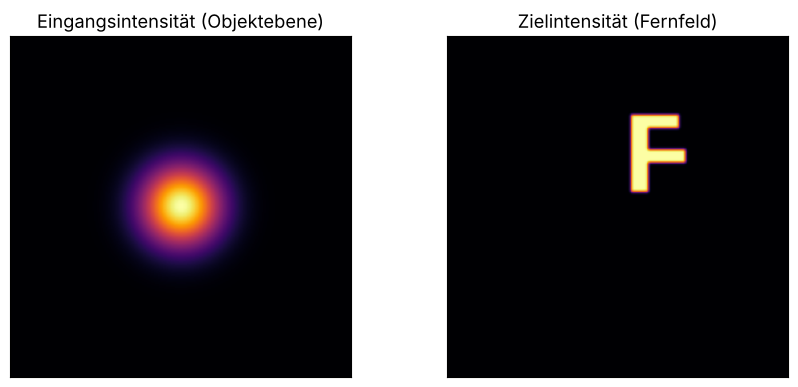

In [2]:
N = 256
x, y, X, Y = grid2d(-N/2, N/2, -N/2, N/2, N)
A_in = np.exp(-(X**2 + Y**2)/(2*30**2))
I_in = A_in**2

F_poly_x = np.array([10, 22, 22, 50, 50, 22, 22, 45, 45, 10])
F_poly_y = np.array([10, 10, 32, 32, 42, 42, 58, 58, 68, 68])
target = mask_from_polygon(x, y, F_poly_x, F_poly_y).astype(float)
target = gaussian_filter(target, 1.0)
I_target = target*np.sum(I_in)/np.sum(target)  # gleiche Energie; FT_unitary erhält sum(|U|^2)
support = target > 0.5

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(I_in, cmap="inferno"); axes[0].set_title("Eingangsintensität (Objektebene)")
axes[1].imshow(I_target, cmap="inferno"); axes[1].set_title("Zielintensität (Fernfeld)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## 2. Gerchberg-Saxton

Als Gütemaße verwenden wir die **Effizienz** (Anteil der Energie im Zielgebiet)
und die **Ungleichförmigkeit** (relative Standardabweichung der Intensität im
Inneren des Buchstabens). Um sie in jeder Iteration mitzuschreiben, ersetzen wir
die Abbruchbedingung des Algorithmus durch eine Funktion, die mitprotokolliert,
ein Beispiel für den modularen Aufbau von `IFTABase`.

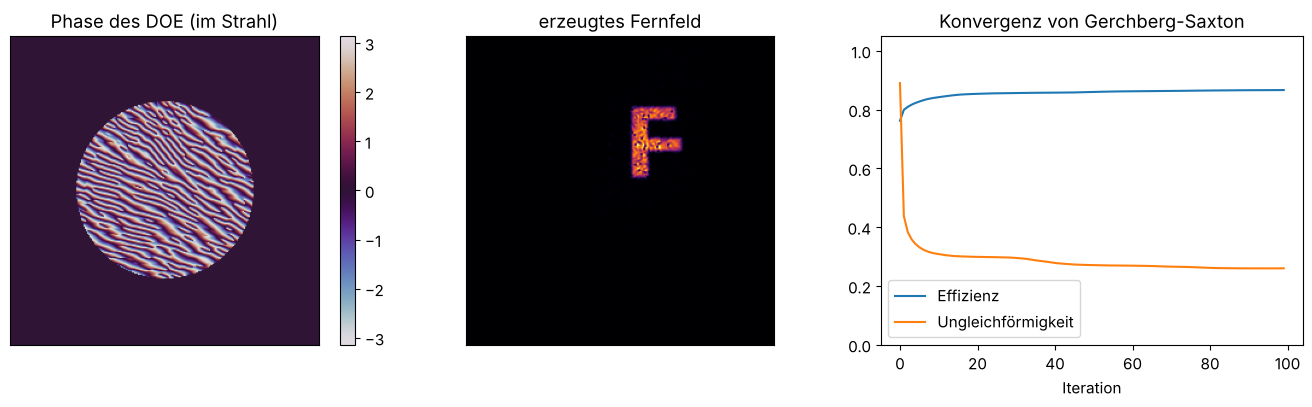

In [3]:
def quality(img):
    I = np.abs(img)**2
    eta = I[support].sum()/I.sum()
    inner = target > 0.9
    nonunif = np.std(I[inner])/np.mean(I[inner])
    return eta, nonunif

def run_logged(alg_class, n_iter, start, **kwargs):
    alg = alg_class(I_in, I_target, n_iter, **kwargs)
    log = []
    def stop(curr_obj, curr_img, old_obj, old_img, i):
        # curr_img ist hier schon mit der Zielamplitude überschrieben, deshalb
        # rechnen wir das tatsächliche Bild aus dem aktuellen Objekt:
        if i > 1:
            log.append(quality(alg.to_image_space(curr_obj, None, None, None, i)))
        return i > n_iter
    alg.stopping_condition = stop
    obj, img, _ = run_quietly(alg, start)
    return obj, alg.to_image_space(obj, None, None, None, 0), np.array(log)

rng = np.random.default_rng(3)
start = np.sqrt(I_target)*np.exp(2j*np.pi*rng.random((N, N)))
obj_gs, img_gs, log_gs = run_logged(ifta.GS, 100, start)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
im = axes[0].imshow(np.angle(obj_gs)*(A_in > 0.05*A_in.max()), cmap="twilight", vmin=-np.pi, vmax=np.pi)
axes[0].set_title("Phase des DOE (im Strahl)"); fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(np.abs(img_gs)**2, cmap="inferno"); axes[1].set_title("erzeugtes Fernfeld")
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
axes[2].plot(log_gs[:, 0], label="Effizienz")
axes[2].plot(log_gs[:, 1], label="Ungleichförmigkeit")
axes[2].set_xlabel("Iteration"); axes[2].set_ylim(0, 1.05); axes[2].legend()
axes[2].set_title("Konvergenz von Gerchberg-Saxton")
fig.tight_layout()

Das Fernfeld ist **gesprenkelt** (Speckle): Wo die Phase im Zielgebiet springt,
entstehen Nullstellen. Gerchberg-Saxton bleibt typischerweise nach wenigen
Iterationen in einem solchen lokalen Minimum stecken.

## 3. Auswege aus der Stagnation: Rückkopplung oder bessere Startphase

`IFTA_HOO` mischt das Bild der vorigen Iteration mit einem Korrekturterm
(Parameter $\beta = 0.9$), um den Algorithmus aus lokalen Minima zu stoßen.
Eine andere, oft wirksamere Maßnahme ist eine **glatte Startphase**: Eine
zufällige Startphase legt viele Phasenwirbel ins Zielgebiet, deren Nullstellen
der Algorithmus nicht mehr loswird. Eine quadratische Startphase (wie von einer
Linse) erzeugt dagegen kaum Wirbel.

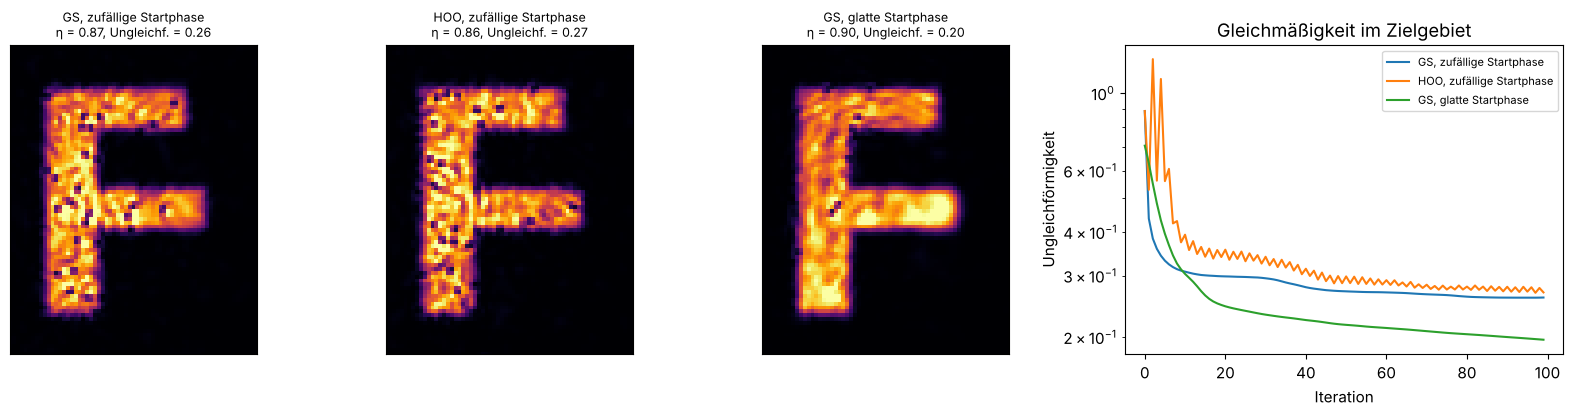

In [4]:
quad_phase = 0.01*((X - 30)**2 + (Y - 39)**2)  # glatt, zentriert auf dem "F"
start_smooth = np.sqrt(I_target)*np.exp(1j*quad_phase)
obj_hoo, img_hoo, log_hoo = run_logged(ifta.IFTA_HOO, 100, start)
obj_sm, img_sm, log_sm = run_logged(ifta.GS, 100, start_smooth)

runs = (("GS, zufällige Startphase", img_gs, log_gs), ("HOO, zufällige Startphase", img_hoo, log_hoo),
        ("GS, glatte Startphase", img_sm, log_sm))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for ax, (name, img, log) in zip(axes, runs):
    I = np.abs(img)**2
    ax.imshow(I, cmap="inferno", vmax=np.percentile(I, 99.9))
    ax.set_xlim(N/2, N/2 + 64); ax.set_ylim(N/2, N/2 + 80); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nη = {log[-1, 0]:.2f}, Ungleichf. = {log[-1, 1]:.2f}", fontsize=9)
    axes[3].plot(log[:, 1], label=name)
axes[3].set_yscale("log"); axes[3].set_xlabel("Iteration"); axes[3].set_ylabel("Ungleichförmigkeit")
axes[3].legend(fontsize=8); axes[3].set_title("Gleichmäßigkeit im Zielgebiet")
fig.tight_layout()

In diesem Beispiel bringt die Rückkopplung von HOO wenig, die glatte Startphase
dagegen eine sichtbar gleichmäßigere Ausleuchtung bei etwas höherer Effizienz.
Ganz verschwinden die Speckle nicht: Das Zielmuster ist schärfer, als es die
endliche Größe des Eingangsstrahls erlaubt.

## 4. Phasenquantisierung: Wie viele Stufen braucht das Element?

Lithographisch hergestellte DOEs haben nur $2^n$ Phasenstufen. `digitize_phase()`
rundet die Phase entsprechend. Mit nur **zwei** Stufen ist die Transmission
reell, ihr Fernfeld daher punktsymmetrisch: Neben dem "F" erscheint sein um
$180°$ gedrehtes Zwillingsbild, und die Effizienz kann höchstens etwa 40 % sein.
Mit 4, 8, 16 Stufen nähert sich das Ergebnis dem kontinuierlichen Element an.
Die skalare Theorie gibt für die Effizienz der Ordnung, in die das Element
gerade "zielt", $\mathrm{sinc}^2(1/L)$ bei $L$ Stufen.

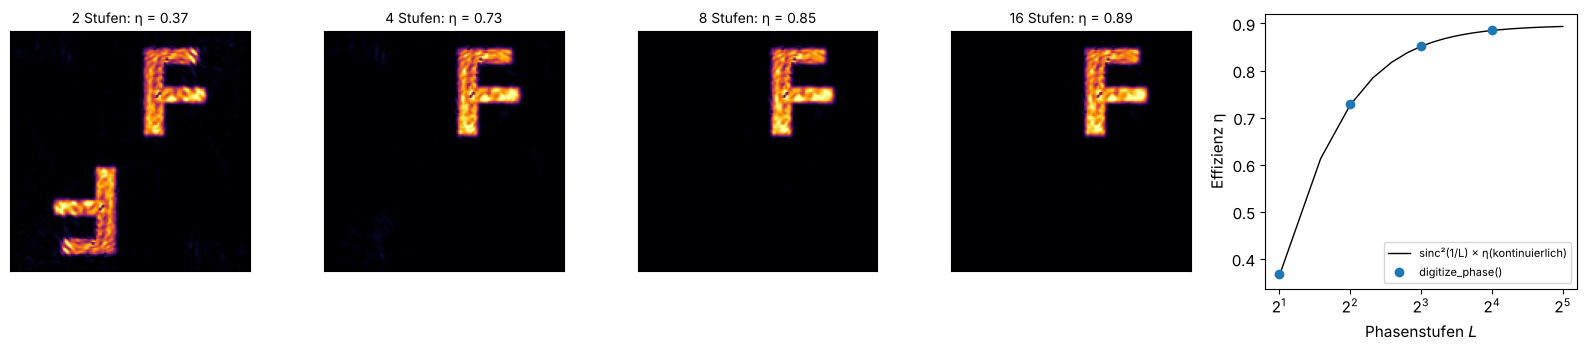

In [5]:
levels = (2, 4, 8, 16)
fig, axes = plt.subplots(1, len(levels) + 1, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1]*len(levels) + [1.3]})
etas = []
for ax, L in zip(axes, levels):
    obj_q = ifta.digitize_phase(obj_sm, L)
    img_q = ifta.FT_unitary(obj_q)
    eta, nonunif = quality(img_q)
    etas.append(eta)
    ax.imshow(np.abs(img_q)**2, cmap="inferno", vmax=np.percentile(np.abs(img_q)**2, 99.9))
    ax.set_title(f"{L} Stufen: η = {eta:.2f}", fontsize=10)
    ax.set_xlim(N/2 - 80, N/2 + 80); ax.set_ylim(N/2 - 80, N/2 + 80); ax.set_xticks([]); ax.set_yticks([])
Ls = np.arange(2, 33)
axes[-1].plot(Ls, np.sinc(1/Ls)**2*log_sm[-1, 0], "k-", lw=1, label="sinc²(1/L) × η(kontinuierlich)")
axes[-1].plot(levels, etas, "o", label="digitize_phase()")
axes[-1].set_xscale("log", base=2); axes[-1].set_xlabel("Phasenstufen $L$"); axes[-1].set_ylabel("Effizienz η")
axes[-1].legend(fontsize=8)
fig.tight_layout()